## introduction
Research background and motivation.

Why exchange rates may influence international tourism.

Why you selected London and the period 2010–2019.

Why you selected nine countries across six currency groups.

The three data sources and their respective roles.

In [107]:
import sys
import pandas as pd
import numpy as np
import requests
from bs4 import BeautifulSoup
from io import BytesIO, StringIO
from pathlib import Path
from urllib.parse import urljoin

print(sys.executable)

/Users/clairek/Desktop/SDPA/summative-coursework-v1/Component2/.venv/bin/python


# 2.1 Collect and clean international visits to London data

In [108]:
# 1. Dataset webpage
page_url = (
    "https://www.data.gov.uk/dataset/"
    "08ff246b-176a-40cc-af3c-2076dfbb7a92/"
    "number-of-international-visitors-to-london1"
)

# 2. Scrape the webpage
response = requests.get(page_url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

# 3. Find the CSV download link
csv_url = None

for link in soup.find_all("a", href=True):
    href = link["href"]
    if "international-visitors-london-raw.csv" in href:
        csv_url = urljoin(page_url, href)
        break

if csv_url is None:
    raise ValueError("CSV download link not found")

print("CSV URL:", csv_url)

# 4. Download the CSV
csv_response = requests.get(csv_url, timeout=60)
csv_response.raise_for_status()

# 5. Save the original dataset
Path("datasets").mkdir(exist_ok=True)

Path("datasets/international-visitors-london-raw.csv").write_bytes(
    csv_response.content
)

# 6. Load into pandas
rawdata = pd.read_csv(
    BytesIO(csv_response.content),
    encoding="cp1252"
)

print(rawdata.shape)
print(rawdata.head())

CSV URL: https://data.london.gov.uk/download/20opj/b1e0f953-4c8a-4b45-95f5-e0d143d5641e/international-visitors-london-raw.csv
(61462, 11)
   year        quarter   market     dur_stay mode        purpose     area  \
0  2002  January-March  Belgium  1-3  nights  Air        Holiday   LONDON   
1  2002  January-March  Belgium  1-3  nights  Air       Business   LONDON   
2  2002  January-March  Belgium  1-3  nights  Air            VFR   LONDON   
3  2002  January-March  Belgium  1-3  nights  Air  Miscellaneous   LONDON   
4  2002  January-March  Belgium  1-3  nights  Sea       Business   LONDON   

   Visits (000s)  Spend (£m)  Nights (000s)  sample  
0       3.572186    0.969138       6.954456       5  
1       9.284226    2.399577      12.604959      19  
2       0.877182    0.089833       2.153128       3  
3       0.163874    0.010160       0.163874       1  
4       1.648670    0.016789       1.650300       1  


In [109]:
# checking missing value and shape of the original data
print("Missing_value")
print(rawdata.isna().sum())
print("\n Shape")
print(rawdata.shape)

rawdata.head()

Missing_value
year             0
quarter          0
market           0
dur_stay         0
mode             0
purpose          0
area             0
Visits (000s)    0
Spend (£m)       0
Nights (000s)    0
sample           0
dtype: int64

 Shape
(61462, 11)


,year,quarter,market,dur_stay,mode,purpose,area,Visits (000s),Spend (£m),Nights (000s),sample
0,2002,January-March,Belgium,1-3 nights,Air,Holiday,LONDON,3.572186,0.969138,6.954456,5
1,2002,January-March,Belgium,1-3 nights,Air,Business,LONDON,9.284226,2.399577,12.604959,19
2,2002,January-March,Belgium,1-3 nights,Air,VFR,LONDON,0.877182,0.089833,2.153128,3
3,2002,January-March,Belgium,1-3 nights,Air,Miscellaneous,LONDON,0.163874,0.010160,0.163874,1
4,2002,January-March,Belgium,1-3 nights,Sea,Business,LONDON,1.648670,0.016789,1.650300,1


In [110]:
# making a datafram with year between 2010-2019 / 10y)
visits_df = rawdata.copy()

visits_df["year"] = pd.to_numeric(visits_df["year"], errors="coerce")

visits_df = visits_df[visits_df["year"].between(2010, 2019)].copy()
visits_df["year"] = visits_df["year"].astype(int)


In [111]:
visits_df['visits'] = visits_df['Visits (000s)']*1000
visits_df['spend_gbp'] = visits_df['Spend (£m)']*1_000_000
visits_df['total_nights'] = visits_df['Nights (000s)']*1000

visits_df = visits_df.drop(columns = ['Visits (000s)', 'Spend (£m)', 'Nights (000s)'])

visits_df = visits_df.rename(columns={
    "market": "country",
    "dur_stay": "stay_nights",
    "mode": "transport",
    "purpose": "purpose",
    "sample": "sample_size"
})

visits_df = visits_df[['year',
 'quarter',
 'country',
 'purpose',
 'visits',
 'spend_gbp',
 'total_nights',
 'stay_nights',
 'sample_size',
 'transport', 
 'area']]

visits_df.head()

,year,quarter,country,purpose,visits,spend_gbp,total_nights,stay_nights,sample_size,transport,area
27065,2010,January-March,Belgium,Holiday,1881.051719,695745.409,4296.884596,1-3 nights,3,Air,LONDON
27066,2010,January-March,Belgium,Business,5800.515682,3532986.149,11905.291020,1-3 nights,8,Air,LONDON
27067,2010,January-March,Belgium,VFR,872.630388,401441.261,1348.065287,1-3 nights,2,Air,LONDON
27068,2010,January-March,Belgium,Miscellaneous,1112.400606,74909.571,1112.400606,1-3 nights,4,Air,LONDON
27069,2010,January-March,Belgium,Holiday,6719.158053,1867431.745,14160.314080,1-3 nights,6,Sea,LONDON


In [112]:
#checking the 20 highest visits country
top20 = visits_df.groupby('country')['visits'].sum()
top20 = top20.sort_values(ascending = False).head(20)
top20

country
USA                     2.368507e+07
France                  1.805859e+07
Germany                 1.354122e+07
Italy                   1.280779e+07
Spain                   1.129018e+07
Irish Republic          7.163846e+06
Netherlands             7.032663e+06
Australia               5.995862e+06
Belgium                 4.885504e+06
Sweden                  4.761939e+06
Switzerland             4.612524e+06
Canada                  4.353305e+06
Poland                  4.300265e+06
Norway                  3.881629e+06
Denmark                 3.412831e+06
India                   3.354861e+06
China                   3.340348e+06
Other Eastern Europe    3.318997e+06
Japan                   2.646814e+06
Portugal                2.311114e+06
Name: visits, dtype: float64

In [113]:
# selecting 9 representative countries to analyse
selected_countries = [
    "France", "Germany", "Italy", "Spain",
    "USA", "Australia", "India", "China", "Japan"
]

visits_df = visits_df[visits_df["country"].isin(selected_countries)].copy()
visits_df.head()

,year,quarter,country,purpose,visits,spend_gbp,total_nights,stay_nights,sample_size,transport,area
27093,2010,January-March,France,Holiday,30250.444290,9161917.560,74183.489800,1-3 nights,44,Air,LONDON
27094,2010,January-March,France,Business,15300.038310,5058596.730,28299.960640,1-3 nights,25,Air,LONDON
27095,2010,January-March,France,VFR,11790.341230,2817000.831,25084.421460,1-3 nights,17,Air,LONDON
27096,2010,January-March,France,Study,756.891251,375636.458,2004.865408,1-3 nights,1,Air,LONDON
27097,2010,January-March,France,Miscellaneous,7521.886244,1826383.916,9806.745589,1-3 nights,15,Air,LONDON


### About country selection
Since the purpose of this data analysis is to analyse the interest rate, I priotised countries with different currency zone. At the same time to meet the amount of sample required for statistics, I chose countries with high visits during the 10 years (2010-2019). although other European countries like Netherland showed higher visits, I limited the number of European countries to meet the balance with other currency group.

In [114]:
# clearning data and adding a currency column
visits_df['quarter'] = visits_df['quarter'].replace({
    "January-March": 1,
    "April-June": 2,
    "July-September": 3,
    "October-December": 4
})
 
visits_df["stay_nights"] = (
    visits_df["stay_nights"]
    .str.replace("nights", "", regex=False)
    .str.replace("night", "", regex=False)
    .str.strip()
)
visits_df["year"] = visits_df["year"].astype(int)

currency_map = {
    "France": "EUR",
    "Germany": "EUR",
    "Italy": "EUR",
    "Spain": "EUR",
    "USA": "USD",
    "Australia": "AUD",
    "India": "INR",
    "China": "CNY",
    "Japan": "JPY"
}

# checking the total number of visits all time grouped by countries of same currency
visits_df["currency"] = visits_df["country"].map(currency_map)
visits_df.groupby("currency")["visits"].sum()

currency
AUD    5.995862e+06
CNY    3.340348e+06
EUR    5.569778e+07
INR    3.354861e+06
JPY    2.646814e+06
USD    2.368507e+07
Name: visits, dtype: float64

In [115]:
# featuring 'spend per visit' column by currecy group and visit of purpose
quarterly_visits = (
    visits_df.groupby(
        ["year", "quarter", "currency", "purpose"],
        as_index = False
    )
    .agg(
        visits=("visits", "sum"),
        spend_gbp=("spend_gbp", "sum")
    )
)
quarterly_visits["spend_per_visit"] = quarterly_visits["spend_gbp"] / quarterly_visits["visits"]

In [116]:
print(quarterly_visits['year'].unique())
print(quarterly_visits['quarter'].unique())
print(quarterly_visits['currency'].unique())
print(quarterly_visits['purpose'].unique())
quarterly_visits.describe()

[2010 2011 2012 2013 2014 2015 2016 2017 2018 2019]
[1 2 3 4]
<StringArray>
['AUD', 'CNY', 'EUR', 'INR', 'JPY', 'USD']
Length: 6, dtype: str
<StringArray>
['Business', 'Holiday', 'Miscellaneous', 'Study', 'VFR']
Length: 5, dtype: str


,year,quarter,visits,spend_gbp,spend_per_visit
count,1119.000000,1119.000000,1.119000e+03,1.119000e+03,1119.000000
mean,2014.502234,2.496872,8.464767e+04,5.240886e+07,1352.396322
std,2.884439,1.114123,1.616490e+05,7.787564e+07,2538.319660
min,2010.000000,1.000000,1.846441e+02,1.534418e+04,21.688817
25%,2012.000000,2.000000,7.147120e+03,7.701772e+06,474.426293
50%,2015.000000,3.000000,2.121425e+04,2.244017e+07,746.699844
75%,2017.000000,3.000000,7.243405e+04,5.564561e+07,1420.501997
max,2019.000000,4.000000,1.017166e+06,4.499620e+08,49127.471805


# 2.2 Collect and clean exchange rate data


In [117]:
# 1. dataset webpage
url = (
    "https://www.bankofengland.co.uk/"
    "boeapps/database/fromshowcolumns.asp"
)

params = {
    "Travel": "NIxIRxSUx",
    "FromSeries": "1",
    "ToSeries": "50",
    "DAT": "RNG",
    "FD": "1",
    "FM": "Jan",
    "FY": "2010",
    "TD": "31",
    "TM": "Dec",
    "TY": "2019",
    "CSVF": "TT",
    "html.x": "122",
    "html.y": "24",
    "C": ["DKW", "NSC", "NS9", "DL2", "DL7", "DLM"],
    "Filter": "N"
}
# 2. data request and checking response
response = requests.get(
    url,
    params=params,
    headers={"User-Agent": "UKCitiesStudy/1.0"},
    timeout=60
)

response.raise_for_status()

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

# 3. checking the text in relevant tables
soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table")

print("Number of tables:", len(tables))

for i, table in enumerate(tables):
    print(f"\nTable {i}:")
    print(table.get_text(" ", strip=True)[:500])

Status: 200
Content type: text/html
Number of tables: 2

Table 0:
Date Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS Quarterly average spot exchange rate, Chinese Yuan into Sterling XUQABK89 Quarterly average spot exchange rate, Indian Rupee into Sterling XUQABK97 Quarterly average Spot exchange rate, Euro into Sterling XUQAERS Quarterly average Spot exchange rate, Japanese Yen into Sterling XUQAJYS Quarterly average Spot exchange rate, US $ into Sterling XUQAUSS 31 Mar 10 1.7235 10.6392 71.4874 1.1269 141.3355 1.5584 30 Jun 10 

Table 1:
Necessary cookies Analytics cookies Yes Yes Accept recommended cookies Yes No Proceed with necessary cookies only


In [118]:
# making a dataframe through the relevant table
fx_df= pd.read_html(StringIO(str(tables[0])))[0]

print(fx_df.shape)
print(fx_df.columns.tolist())
print(fx_df.head())

(40, 7)
['Date', 'Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS', 'Quarterly average spot exchange rate, Chinese Yuan into Sterling XUQABK89', 'Quarterly average spot exchange rate, Indian Rupee into Sterling XUQABK97', 'Quarterly average Spot exchange rate, Euro into Sterling XUQAERS', 'Quarterly average Spot exchange rate, Japanese Yen into Sterling XUQAJYS', 'Quarterly average Spot exchange rate, US $ into Sterling XUQAUSS']
        Date  \
0  31 Mar 10   
1  30 Jun 10   
2  30 Sep 10   
3  31 Dec 10   
4  31 Mar 11   

   Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS  \
0                                             1.7235                               
1                                             1.6922                               
2                                             1.7150                               
3                                             1.6009                               
4                  

In [119]:
# renaming the columns matching with the visits data
fx_df = fx_df.rename(columns={
    'Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS': "AUD",
    'Quarterly average spot exchange rate, Chinese Yuan into Sterling XUQABK89': 'CNY',
    'Quarterly average spot exchange rate, Indian Rupee into Sterling XUQABK97': 'INR',
    'Quarterly average Spot exchange rate, Euro into Sterling XUQAERS': 'EUR',
    'Quarterly average Spot exchange rate, Japanese Yen into Sterling XUQAJYS': 'JPY',
    'Quarterly average Spot exchange rate, US $ into Sterling XUQAUSS': 'USD'
    }
)

# creating year and quarter for lookup
fx_df["Date"] = pd.to_datetime(fx_df["Date"], format="%d %b %y")

fx_df["year"] = fx_df["Date"].dt.year
fx_df["quarter"] = fx_df["Date"].dt.quarter

# Remove Date and reorder columns
fx_df = fx_df[["year", "quarter", "AUD", "CNY", "INR", "EUR", "JPY", "USD"]]

# checking the missing value and overall dataframe
print(fx_df.isna().sum())
print(fx_df.shape)
print(fx_df.head())

year       0
quarter    0
AUD        0
CNY        0
INR        0
EUR        0
JPY        0
USD        0
dtype: int64
(40, 8)
   year  quarter     AUD      CNY      INR     EUR       JPY     USD
0  2010        1  1.7235  10.6392  71.4874  1.1269  141.3355  1.5584
1  2010        2  1.6922  10.1734  68.0141  1.1747  137.2062  1.4909
2  2010        3  1.7150  10.4967  71.9827  1.1995  133.0108  1.5510
3  2010        4  1.6009  10.5237  70.8754  1.1639  130.5153  1.5811
4  2011        1  1.5955  10.5470  72.5471  1.1710  131.9404  1.6034


Exchange rates are measured as units of foreign currency per British pound. Therefore, an increase in the exchange rate represents an appreciation of GBP against the corresponding foreign currency.

# 2.3 Collect and clean UK inflation data

In [120]:
# ONS CPI index API
url = (
    "https://www.ons.gov.uk/economy/"
    "inflationandpriceindices/timeseries/d7bt/mm23/data"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

data = response.json()

print(data.keys())
# Extract quarterly observations
cpi_df = pd.DataFrame(data["quarters"])

print(cpi_df.columns.tolist())
print(cpi_df.head())


dict_keys(['years', 'quarters', 'months', 'sourceDatasets', 'relatedDatasets', 'relatedDocuments', 'relatedData', 'versions', 'type', 'uri', 'description'])
['date', 'value', 'label', 'year', 'month', 'quarter', 'sourceDataset', 'updateDate']
      date value    label  year month quarter sourceDataset  \
0  1988 Q1  48.6  1988 Q1  1988            Q1          MM23   
1  1988 Q2  49.5  1988 Q2  1988            Q2          MM23   
2  1988 Q3  49.9  1988 Q3  1988            Q3          MM23   
3  1988 Q4  50.5  1988 Q4  1988            Q4          MM23   
4  1989 Q1  51.0  1989 Q1  1989            Q1          MM23   

                 updateDate  
0  2018-12-19T00:00:00.000Z  
1  2016-01-19T09:30:00.000Z  
2  2016-01-19T09:30:00.000Z  
3  2016-01-19T09:30:00.000Z  
4  2018-12-19T00:00:00.000Z  


In [121]:
# save the CPI extraction CSV file
cpi_monthly_raw = pd.DataFrame(data["months"])

print(cpi_monthly_raw.shape)

cpi_monthly_raw.to_csv(
    "datasets/cpi_monthly_raw.csv",
    index=False
)

(466, 8)


In [122]:
# Keep only the columns needed
cpi_df = cpi_df[["year", "quarter", "value"]].copy()

# Rename the CPI value column
cpi_df = cpi_df.rename(columns={"value": "cpi_index"})

# Convert data types and filter 2010 - 2019
cpi_df["year"] = pd.to_numeric(cpi_df["year"])
cpi_df["quarter"] = (
    cpi_df["quarter"]
    .str.replace("Q", "", regex=False)
    .astype(int)
)

cpi_df["cpi_index"] = pd.to_numeric(cpi_df["cpi_index"])

cpi_df = cpi_df[cpi_df["year"].between(2010, 2019)].copy()

# Sort chronologically
cpi_df = (cpi_df.sort_values(["year", "quarter"]).reset_index(drop=True))

print(cpi_df.isna().sum())
print(cpi_df.head())
print(cpi_df.shape)

year         0
quarter      0
cpi_index    0
dtype: int64
   year  quarter  cpi_index
0  2010        1       88.2
1  2010        2       89.3
2  2010        3       89.6
3  2010        4       90.5
4  2011        1       91.8
(40, 3)


2015 is the standard point for this CPI data indicating 100

## 2.4 Data Merge

In [123]:
#creataing year and quarter for key to lookup

fx_lookup = fx_df.set_index(["year", "quarter"], verify_integrity=True)
fx_lookup.head()

/var/folders/93/dz_8fh6104x97ksqhx98m8qr0000gn/T/ipykernel_3068/1137649502.py:3: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  fx_lookup = fx_df.set_index(["year", "quarter"], verify_integrity=True)


AUD      CNY      INR     EUR       JPY     USD
year quarter                                                    
2010 1        1.7235  10.6392  71.4874  1.1269  141.3355  1.5584
     2        1.6922  10.1734  68.0141  1.1747  137.2062  1.4909
     3        1.7150  10.4967  71.9827  1.1995  133.0108  1.5510
     4        1.6009  10.5237  70.8754  1.1639  130.5153  1.5811
2011 1        1.5955  10.5470  72.5471  1.1710  131.9404  1.6034

In [124]:
# creating analysis_df and merging exchange rate into visits data

analysis_df = quarterly_visits.copy()
analysis_df["exchange_rate"] = analysis_df.apply(
    lambda row: fx_lookup.loc[
        (row["year"], row["quarter"]), row["currency"]],
    axis=1
)

analysis_df.head()    

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate
0,2010,1,AUD,Business,12275.242836,1.908936e+07,1555.110309,1.7235
1,2010,1,AUD,Holiday,34089.785771,1.960992e+07,575.243273,1.7235
2,2010,1,AUD,Miscellaneous,6276.200801,1.071195e+06,170.675664,1.7235
3,2010,1,AUD,Study,196.247861,2.384570e+04,121.508086,1.7235
4,2010,1,AUD,VFR,29439.100163,1.739649e+07,590.931410,1.7235


In [125]:
# merging inflation rate into analysis_df

analysis_df = analysis_df.merge(
    cpi_df,
    on=["year", "quarter"],
    how="left",
    validate="many_to_one"
)
analysis_df.head()

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index
0,2010,1,AUD,Business,12275.242836,1.908936e+07,1555.110309,1.7235,88.2
1,2010,1,AUD,Holiday,34089.785771,1.960992e+07,575.243273,1.7235,88.2
2,2010,1,AUD,Miscellaneous,6276.200801,1.071195e+06,170.675664,1.7235,88.2
3,2010,1,AUD,Study,196.247861,2.384570e+04,121.508086,1.7235,88.2
4,2010,1,AUD,VFR,29439.100163,1.739649e+07,590.931410,1.7235,88.2


In [126]:
# validate the result

print("Shape:", analysis_df.shape)

print("\nMissing values:")
print(analysis_df.isna().sum())

assert len(analysis_df) == len(quarterly_visits)
assert analysis_df["exchange_rate"].notna().all()
assert analysis_df["cpi_index"].notna().all()


Shape: (1119, 9)

Missing values:
year               0
quarter            0
currency           0
purpose            0
visits             0
spend_gbp          0
spend_per_visit    0
exchange_rate      0
cpi_index          0
dtype: int64


In [127]:
# Inflation adjusted total expenditure
analysis_df["real_spend_gbp"] = analysis_df["spend_gbp"] * 100 / analysis_df["cpi_index"]
# Inflation adjusted expenditure per visit
analysis_df["real_spend_per_visit"] = analysis_df["spend_per_visit"] * 100 / analysis_df["cpi_index"]

analysis_df.head()

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit
0,2010,1,AUD,Business,12275.242836,1.908936e+07,1555.110309,1.7235,88.2,2.164326e+07,1763.163616
1,2010,1,AUD,Holiday,34089.785771,1.960992e+07,575.243273,1.7235,88.2,2.223347e+07,652.203257
2,2010,1,AUD,Miscellaneous,6276.200801,1.071195e+06,170.675664,1.7235,88.2,1.214507e+06,193.509824
3,2010,1,AUD,Study,196.247861,2.384570e+04,121.508086,1.7235,88.2,2.703594e+04,137.764270
4,2010,1,AUD,VFR,29439.100163,1.739649e+07,590.931410,1.7235,88.2,1.972391e+07,669.990261


In [128]:
observation_counts = analysis_df.groupby(["currency", "purpose"]).size().unstack()

display(observation_counts)

purpose,Business,Holiday,Miscellaneous,Study,VFR
currency,,,,,
AUD,40,40,40,14,40
CNY,40,40,37,26,40
EUR,40,40,40,40,40
INR,40,40,40,22,40
JPY,40,40,37,24,40
USD,40,40,40,39,40


Since the shape of analysis_df was (1119, 11), checked missing point(81 = 1200-1119) by deviding data into currency and purpose. It showed some missing observation (max = 40) in 'Miscellaneous' and 'Study' category. Since it doesn't mean 0 visits and the portion of the purposes is small actually, I didn't fill the missing observation.

## 3. Exploratory Data Analysis

### 3.1 Visitor and expenditure composition

In [129]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

# creating a dataframe for eda
eda_df = analysis_df.copy()

# creating date column to make graph
eda_df["date"] = pd.to_datetime({
    "year": eda_df["year"],
    "month": eda_df["quarter"] * 3 - 2,
    "day": 1
})

eda_df = eda_df.sort_values("date")
eda_df.head()

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
0,2010,1,AUD,Business,12275.242836,1.908936e+07,1555.110309,1.7235,88.2,2.164326e+07,1763.163616,2010-01-01
29,2010,1,USD,VFR,67131.836590,3.122437e+07,465.120201,1.5584,88.2,3.540178e+07,527.347167,2010-01-01
28,2010,1,USD,Study,2901.675403,8.615793e+06,2969.247822,1.5584,88.2,9.768473e+06,3366.494129,2010-01-01
27,2010,1,USD,Miscellaneous,37931.614830,9.568659e+06,252.260780,1.5584,88.2,1.084882e+07,286.009955,2010-01-01
26,2010,1,USD,Holiday,95805.027966,5.918010e+07,617.713956,1.5584,88.2,6.709762e+07,700.355960,2010-01-01


### 3.2 Market-specific exploratory analysis

In [130]:
#renaming x and y lims for graphs
market_names = {
    "AUD": "Australia",
    "CNY": "China",
    "EUR": "4 EU countries",
    "INR": "India",
    "JPY": "Japan",
    "USD": "USA"
}

purpose_colors = {
    "Holiday": "#4C78A8",
    "Business": "#F58518",
    "VFR": "#54A24B",
    "Study": "#B279A2",
    "Miscellaneous": "#9D755D"
}

purpose_order = ["Holiday", "Business", "VFR", "Study", "Miscellaneous"]

In [131]:
# function for stacked bar chart
def plot_purpose_share(totals, title, xlabel):
    """Plot market-level percentages by travel purpose from a totals table."""
    percentages = totals.div(totals.sum(axis=1), axis=0) * 100
    percentages = percentages.reindex(columns=purpose_order, fill_value=0)
    percentages = percentages.rename(index=market_names)

    ax = percentages.plot(
        kind="barh", stacked=True, figsize=(12, 6),
        color=[purpose_colors[p] for p in purpose_order],
        width=0.7, edgecolor="white"
    )
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Visitor market")
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=100))
    ax.legend(title="Purpose of visit", loc="upper center",
              bbox_to_anchor=(0.5, -0.15), ncol=5)
    ax.invert_yaxis()

    for bars in ax.containers:
        labels = [f"{bar.get_width():.1f}%" if bar.get_width() >= 5 else ""
                  for bar in bars]
        ax.bar_label(bars, labels=labels, label_type="center",
                     fontsize=10, color="white")
    plt.tight_layout()
    plt.show()


In [132]:
    
# accounting the total number of visits grouped by currency and purpose
purpose_visits = (
    analysis_df.groupby(["currency", "purpose"])["visits"]
    .sum()
    .unstack(fill_value=0)
)

display(purpose_visits)


purpose,Business,Holiday,Miscellaneous,Study,VFR
currency,,,,,
AUD,5.013165e+05,3.245833e+06,4.504966e+05,13421.012983,1.784796e+06
CNY,5.611808e+05,2.099306e+06,1.617413e+05,112815.772441,4.053036e+05
EUR,9.331510e+06,3.108807e+07,2.227408e+06,581606.388555,1.246919e+07
INR,7.819492e+05,1.377682e+06,1.880702e+05,41125.177923,9.660348e+05
JPY,6.875114e+05,1.543961e+06,1.003183e+05,56512.149481,2.585107e+05
USD,5.366715e+06,1.148272e+07,2.290177e+06,311230.994927,4.234231e+06


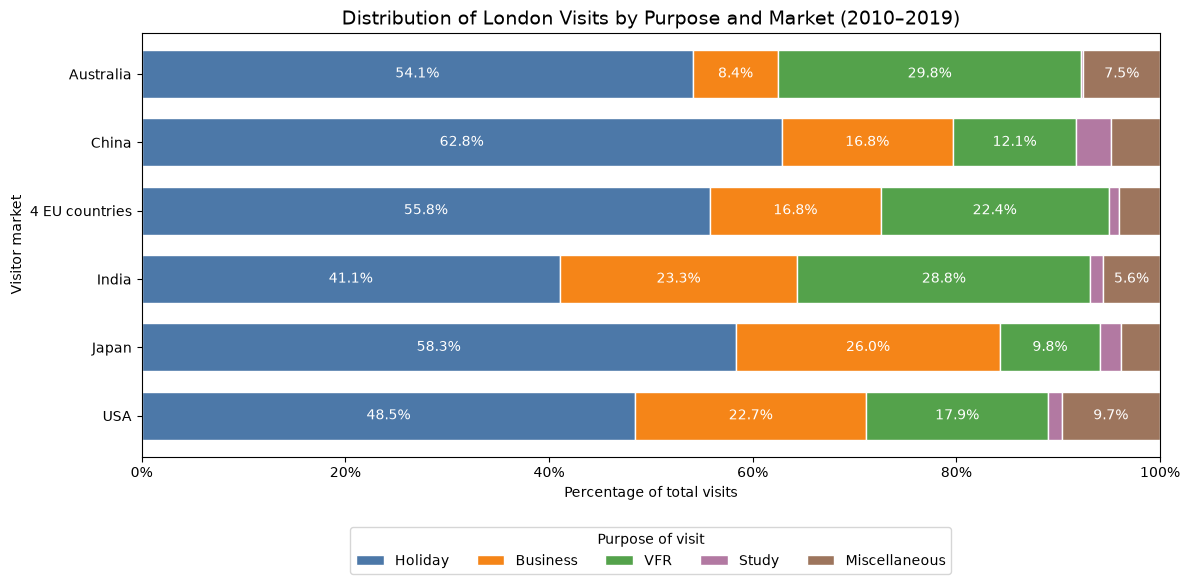

In [133]:
# creating stacked bar chart for visits with proportion of purpose for each country
plot_purpose_share(
    purpose_visits,
    "Distribution of London Visits by Purpose and Market (2010–2019)",
    "Percentage of total visits"
)

In [134]:
# accounting the total spending grouped by currency and purpose
purpose_spend = (
    analysis_df.groupby(["currency", "purpose"])["real_spend_gbp"]
    .sum()
    .unstack(fill_value=0)
)

display(purpose_spend)

purpose,Business,Holiday,Miscellaneous,Study,VFR
currency,,,,,
AUD,9.396657e+08,2.387524e+09,2.480604e+08,2.775084e+07,1.276027e+09
CNY,9.760917e+08,2.529638e+09,3.335110e+08,7.268217e+08,4.898249e+08
EUR,5.192103e+09,1.287731e+10,1.273348e+09,9.821995e+08,3.720377e+09
INR,1.138218e+09,8.064154e+08,2.226163e+08,9.337136e+07,5.228376e+08
JPY,7.558920e+08,1.166668e+09,8.431811e+07,2.910624e+08,1.594737e+08
USD,7.082516e+09,7.920481e+09,1.015677e+09,1.180895e+09,2.110702e+09


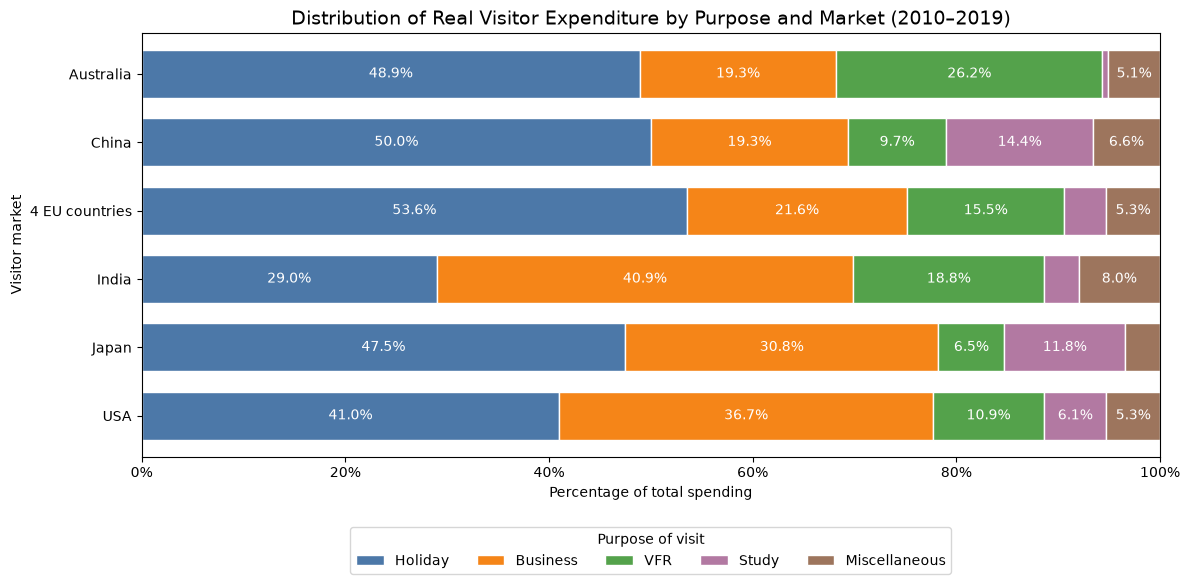

In [135]:
# creating stacked bar chart for total spending with proportion of purpose for each country
plot_purpose_share(
    purpose_spend,
    "Distribution of Real Visitor Expenditure by Purpose and Market (2010–2019)",
    "Percentage of total spending"
)

#### Key observations from visitor demand and expenditure distributions

India: Business visits account for 23.3% of total visits but contribute 40.9% of total expenditure, indicating relatively high expenditure per business visit.

Japan: Holiday visits represent 58.3% of total visits but account for only 47.5% of total expenditure, suggesting that holiday visitors spend less per visit than the overall market average.

China: Despite representing a relatively small proportion of total visits, study-related visits contribute 14.4% of total expenditure, highlighting their economic significance.

Australia: Visiting Friends and Relatives (VFR) accounts for 29.8% of total visits and 26.2% of total expenditure, demonstrating the relative importance of socially motivated travel within the Australian market.

USA: Business visits represent 22.7% of total visits but contribute 36.7% of total expenditure, suggesting relatively high expenditure per business visit.

Selected EU countries: Holiday visits account for 55.8% of total visits and 53.6% of total expenditure. The relatively small difference between these shares suggests that expenditure per holiday visit is close to the overall market average.

### 3.2 Market-specific exploratory analysis

In [136]:
# function for time series of line graph
def plot_market_trend(market_df, currency, variable, ylabel, purpose):
    """Compare one market and purpose time series with its exchange rate."""
    fig, ax1 = plt.subplots(figsize=(13, 5))
    ax1.plot(
        market_df["date"], market_df[variable],
        color=purpose_colors[purpose], linewidth=2,
        marker="o", markersize=3, label=ylabel
    )
    ax1.set_xlabel("Year")
    ax1.set_ylabel(ylabel)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

    ax2 = ax1.twinx()
    ax2.plot(
        market_df["date"], market_df["exchange_rate"],
        color="black", linestyle="--", linewidth=2,
        label="Exchange rate"
    )
    ax2.set_ylabel(f"Exchange rate ({currency} per GBP)")
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax1.legend(loc="upper left")
    ax2.legend(loc="upper right")
    ax1.grid(alpha=0.2)
    ax1.set_title(
        f"{market_names[currency]}: {ylabel} and Exchange Rate (2010–2019)"
    )
    plt.tight_layout()
    plt.show()

#### 3.2.1 Chinese Study visits

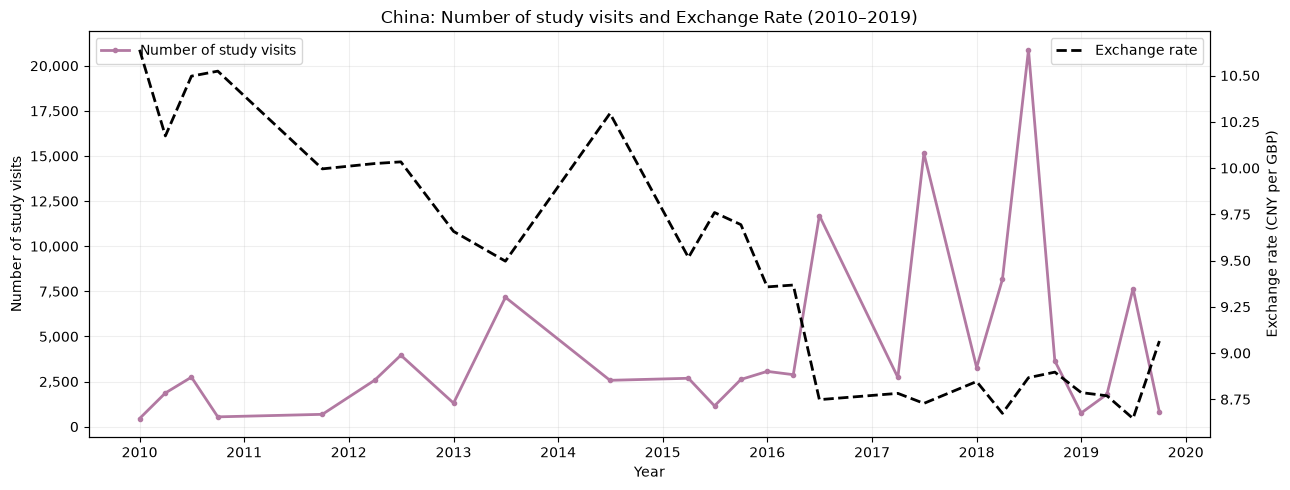

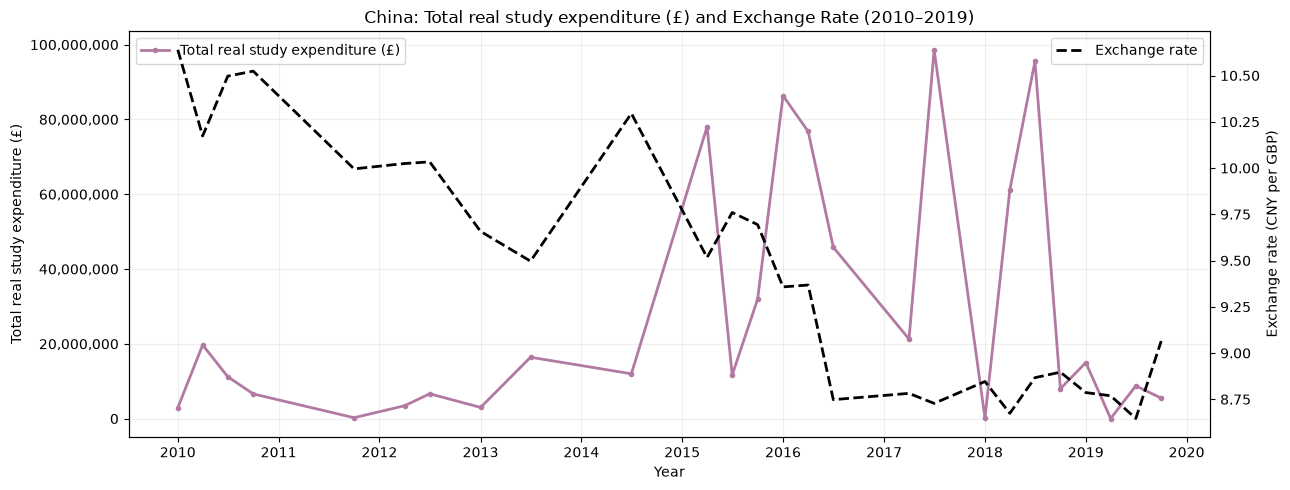

In [137]:
# time series line graph showing visits and spending with CNY exchange rate
china_study_df = eda_df[(eda_df["purpose"] == "Study") & (eda_df["currency"] == "CNY")]
plot_market_trend(china_study_df, "CNY", "visits",
                  "Number of study visits", "Study")
plot_market_trend(china_study_df, "CNY", "real_spend_gbp",
                  "Total real study expenditure (£)", "Study")

Chinese study-related visits exhibit seasonal fluctuations, with visitor numbers appearing to peak in the third quarter. This pattern may reflect the beginning of the academic year in the UK.

An apparent negative relationship between exchange rates and visitor demand can also be observed, particularly between 2016 and 2019, when the exchange rate was approximately 10% lower than in earlier periods.

Additionally, some peaks in total expenditure are not accompanied by corresponding increases in visitor numbers. This suggests substantial variation in expenditure per visit and warrants further investigation of potential outliers.



In [138]:
china_edu_df = china_study_df.copy()
china_edu_df.describe()

,year,quarter,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
count,26.000000,26.000000,26.000000,2.600000e+01,26.000000,26.000000,26.000000,2.600000e+01,26.000000,26
mean,2015.000000,2.538462,4339.068171,2.843151e+07,8164.018695,9.455369,100.157692,2.795468e+07,8170.367922,2015-05-20 15:41:32.307692
min,2010.000000,1.000000,452.070057,3.894805e+04,21.688817,8.646200,88.200000,3.612991e+04,20.119496,2010-01-01 00:00:00
25%,2012.250000,2.000000,1428.013683,5.958292e+06,2245.580880,8.801275,96.500000,5.765963e+06,2217.473172,2012-08-16 00:00:00
50%,2015.500000,3.000000,2705.429136,1.183636e+07,5260.571677,9.432100,100.200000,1.182454e+07,5542.316274,2015-11-16 00:00:00
75%,2018.000000,3.000000,3880.428657,4.268696e+07,9958.737019,10.017100,105.450000,4.235372e+07,10448.837989,2018-03-09 12:00:00
max,2019.000000,4.000000,20885.622020,1.022709e+08,29130.636140,10.639200,108.500000,9.862189e+07,29101.534606,2019-10-01 00:00:00
std,3.187475,1.028816,4903.059313,3.380096e+07,8688.616064,0.659051,6.109741,3.278161e+07,8629.526208,NaN


In [139]:
# catching outlier data for 'real_spend per visit' in CNY and study data
q1 = china_edu_df["real_spend_per_visit"].quantile(0.25)
q3 = china_edu_df["real_spend_per_visit"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = china_edu_df[
    (china_edu_df["real_spend_per_visit"] > upper) |
    (china_edu_df["real_spend_per_visit"] < lower)
]

print(outliers)

     year  quarter currency purpose       visits    spend_gbp  \
593  2015        2      CNY   Study  2681.529045  78114646.91   
678  2016        1      CNY   Study  3063.827276  86168518.07   
706  2016        2      CNY   Study  2880.953550  77082794.19   

     spend_per_visit  exchange_rate  cpi_index  real_spend_gbp  \
593     29130.636140         9.5164      100.1    7.803661e+07   
678     28124.469922         9.3576       99.8    8.634120e+07   
706     26756.000349         9.3676      100.4    7.677569e+07   

     real_spend_per_visit       date  
593          29101.534606 2015-04-01  
678          28180.831585 2016-01-01  
706          26649.402738 2016-04-01  


The real spend_per_vitis actually shows some outlier in 2015, 2016 based on the 1.5*IQR rule. However due to the limit of data as we observed in missing value (only 26 data out of 40), the interpretation toward the seasonality or outlier needs further analysis.

#### 3.2.2 European Holiday visits

In [140]:
# creating dataframe of EUR & holiday
holiday_eur_df = eda_df[(eda_df["purpose"] == "Holiday") & (eda_df["currency"] == "EUR")].copy()
display(holiday_eur_df.head())

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
11,2010,1,EUR,Holiday,648599.372038,2.467951e+08,380.504690,1.1269,88.2,2.798130e+08,431.411213,2010-01-01
40,2010,2,EUR,Holiday,690094.249701,2.427093e+08,351.704561,1.1747,89.3,2.717909e+08,393.846093,2010-04-01
70,2010,3,EUR,Holiday,805846.995153,3.122840e+08,387.522735,1.1995,89.6,3.485313e+08,432.503053,2010-07-01
98,2010,4,EUR,Holiday,749158.294184,2.816047e+08,375.894816,1.1639,90.5,3.111654e+08,415.353388,2010-10-01
124,2011,1,EUR,Holiday,663220.008434,2.343606e+08,353.367850,1.1710,91.8,2.552948e+08,384.932298,2011-01-01


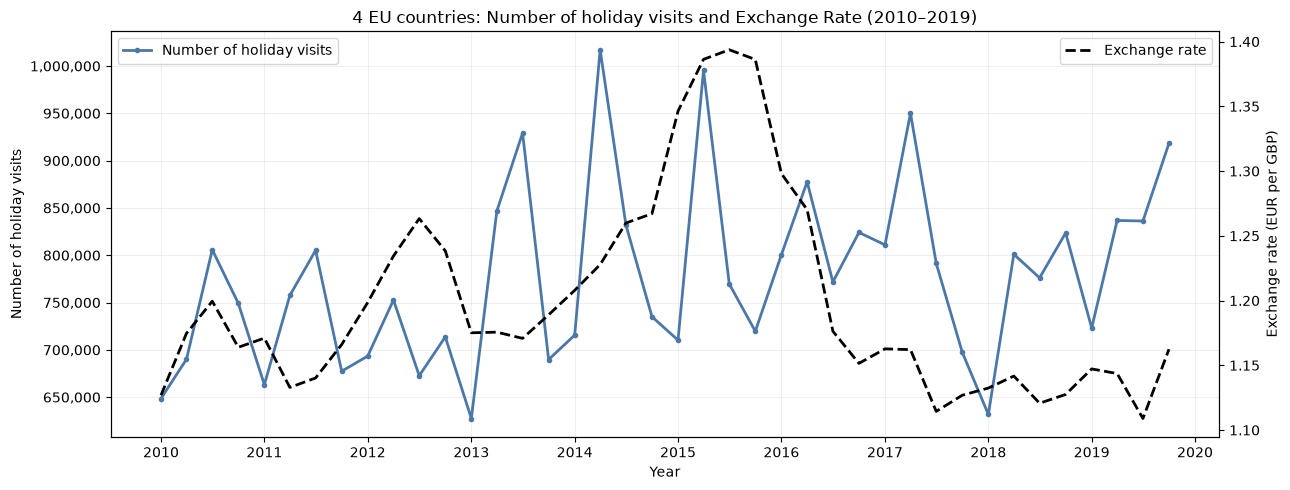

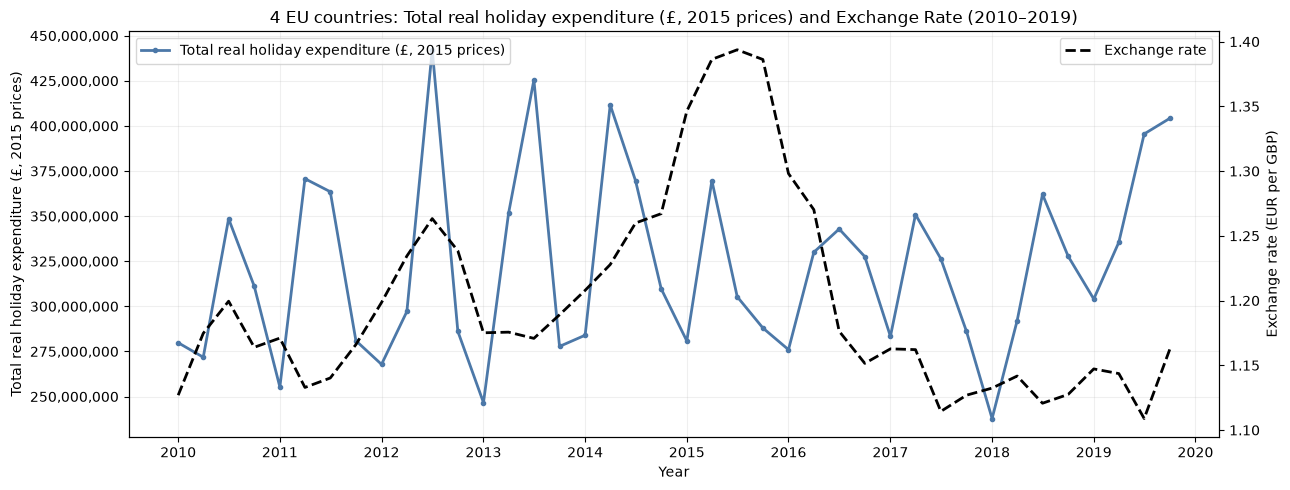

In [141]:
# time series line graph showing visits and spending with EUR exchange rate
plot_market_trend(holiday_eur_df, "EUR", "visits",
                  "Number of holiday visits", "Holiday")
plot_market_trend(holiday_eur_df, "EUR", "real_spend_gbp",
                  "Total real holiday expenditure (£, 2015 prices)", "Holiday")

Holiday visits from the four selected EU countries exhibit strong seasonal fluctuations. However, when the exchange rate peaked, total expenditure showed a noticeable decline, while visitor numbers appeared to be less affected.

One possible explanation is that holidays are often planned and booked in advance, making travel decisions less responsive to short-term exchange-rate fluctuations. In contrast, visitors may have greater flexibility to adjust their expenditure during their stay in response to changes in purchasing power.

In particular, the increase in the exchange rate of approximately 20% around 2015–2016 coincided with a noticeable decrease in total expenditure. Although the exchange rate subsequently declined and stabilised at a lower level, expenditure did not appear to recover immediately.

This delayed recovery may reflect the advance planning involved in international holiday travel or uncertainty regarding future exchange-rate movements. However, these explanations cannot be confirmed through visual inspection alone.

#### 3.2.3 Australian VFR visits

In [142]:
# creating dataframe of AUD & VFR
vfr_aud_df = eda_df[(analysis_df["purpose"] == "VFR") &(analysis_df["currency"] == "AUD")]
display(vfr_aud_df.head())

/var/folders/93/dz_8fh6104x97ksqhx98m8qr0000gn/T/ipykernel_3068/3191641717.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  vfr_aud_df = eda_df[(analysis_df["purpose"] == "VFR") &(analysis_df["currency"] == "AUD")]


,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
4,2010,1,AUD,VFR,29439.100163,1.739649e+07,590.931410,1.7235,88.2,1.972391e+07,669.990261,2010-01-01
33,2010,2,AUD,VFR,39001.792743,2.197440e+07,563.420194,1.6922,89.3,2.460739e+07,630.929669,2010-04-01
63,2010,3,AUD,VFR,66414.286563,3.823736e+07,575.740032,1.7150,89.6,4.267563e+07,642.566999,2010-07-01
92,2010,4,AUD,VFR,32221.053883,2.219298e+07,688.772723,1.6009,90.5,2.452263e+07,761.074832,2010-10-01
118,2011,1,AUD,VFR,28605.953321,1.631077e+07,570.187813,1.5955,91.8,1.776772e+07,621.119622,2011-01-01


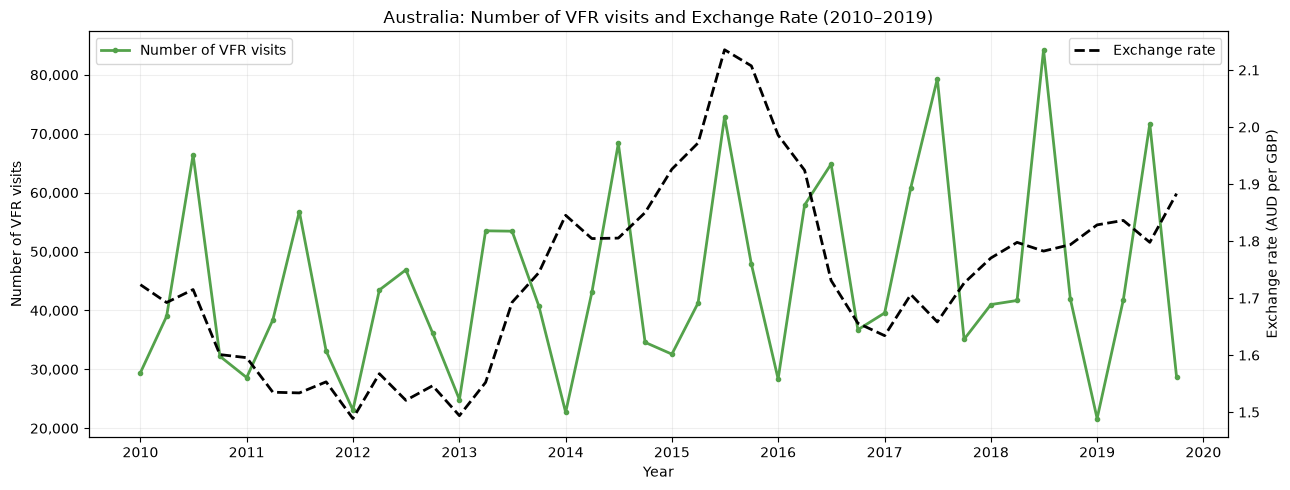

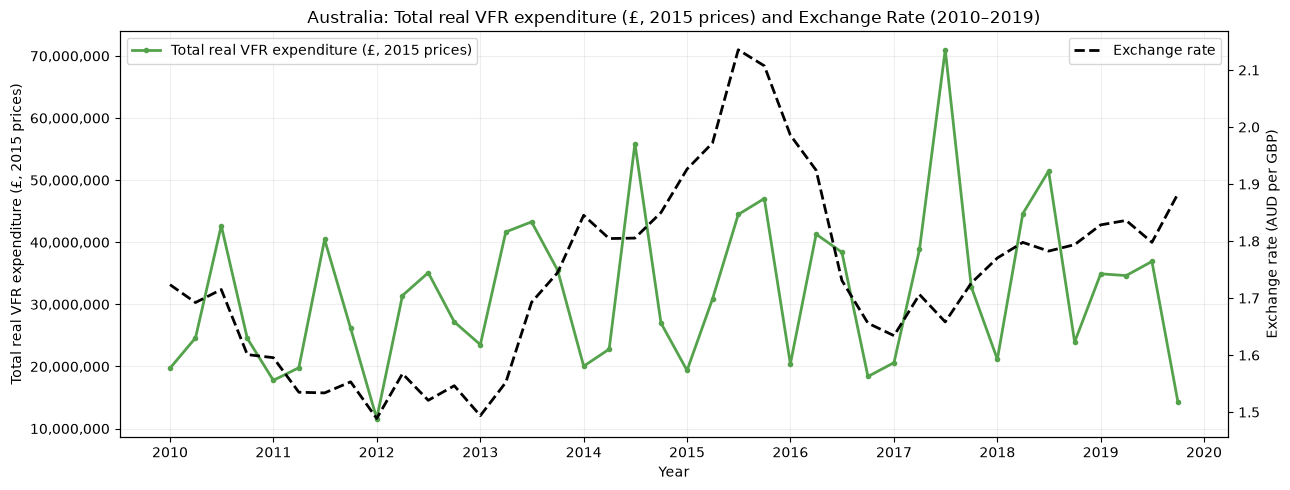

In [143]:
# time series line graph showing visits and spending with AUD exchange rate
plot_market_trend(vfr_aud_df, "AUD", "visits",
                  "Number of VFR visits", "VFR")
plot_market_trend(vfr_aud_df, "AUD", "real_spend_gbp",
                  "Total real VFR expenditure (£, 2015 prices)", "VFR")

Similar to Holiday visits from the selected European countries, Australian VFR visits exhibit strong seasonal fluctuations.

Following the substantial depreciation of GBP against AUD between 2015 and 2017, both visitor numbers and total real expenditure increased, with expenditure showing a particularly pronounced peak in Q3 2017.

The increase in total expenditure appears disproportionately large relative to the increase in visitor numbers, suggesting that expenditure per visit may be more responsive to exchange-rate fluctuations than visitor demand.

However, this observation is based on visual inspection, and further analysis would be required to determine whether the difference reflects exchange-rate sensitivity or other factors.

In 6 different time series graphs, seasonal fluctuation was observed for both visits and total spending. To seperate the effect of season as well as total spending which tends to move according to visits, another violin graphs which shows total visits and spending per visit by quaters combining all time and countries.

### 3.3 Seasonal distribution analysis

In [144]:
# creating quarterly seasonal dataframe integrating visits and real_spending for each purpose
seasonal_df = analysis_df.groupby(
    ["year", "quarter", "purpose"],
    as_index=False
).agg(
    visits=("visits", "sum"),
    real_spend_gbp=("real_spend_gbp", "sum")
)

seasonal_df["real_spend_per_visit"] = (seasonal_df["real_spend_gbp"] / seasonal_df["visits"])

In [145]:
def plot_seasonal_violin(variable, ylabel):

    fig, axes = plt.subplots(
        1, 5, figsize=(18, 5)
    )

    for ax, purpose in zip(axes, purpose_colors):

        purpose_df = seasonal_df[
            seasonal_df["purpose"] == purpose
        ]

        quarterly_data = [
            purpose_df.loc[
                purpose_df["quarter"] == q, variable
            ].dropna()
            for q in range(1, 5)
        ]

        parts = ax.violinplot(
            quarterly_data,
            showmedians=True,
            showextrema=True
        )

        for body in parts["bodies"]:
            body.set_facecolor(purpose_colors[purpose])
            body.set_alpha(0.5)

        ax.set_title(purpose)
        ax.set_xticks([1, 2, 3, 4])
        ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"])
        ax.set_xlabel("Quarter")

        ax.yaxis.set_major_formatter(
            ticker.StrMethodFormatter("{x:,.0f}")
        )

        ax.grid(axis="y", alpha=0.2)

    axes[0].set_ylabel(ylabel)

    fig.suptitle(
        f"Seasonal Distribution of {ylabel} "
        "(2010–2019)"
    )

    plt.tight_layout()
    plt.show()

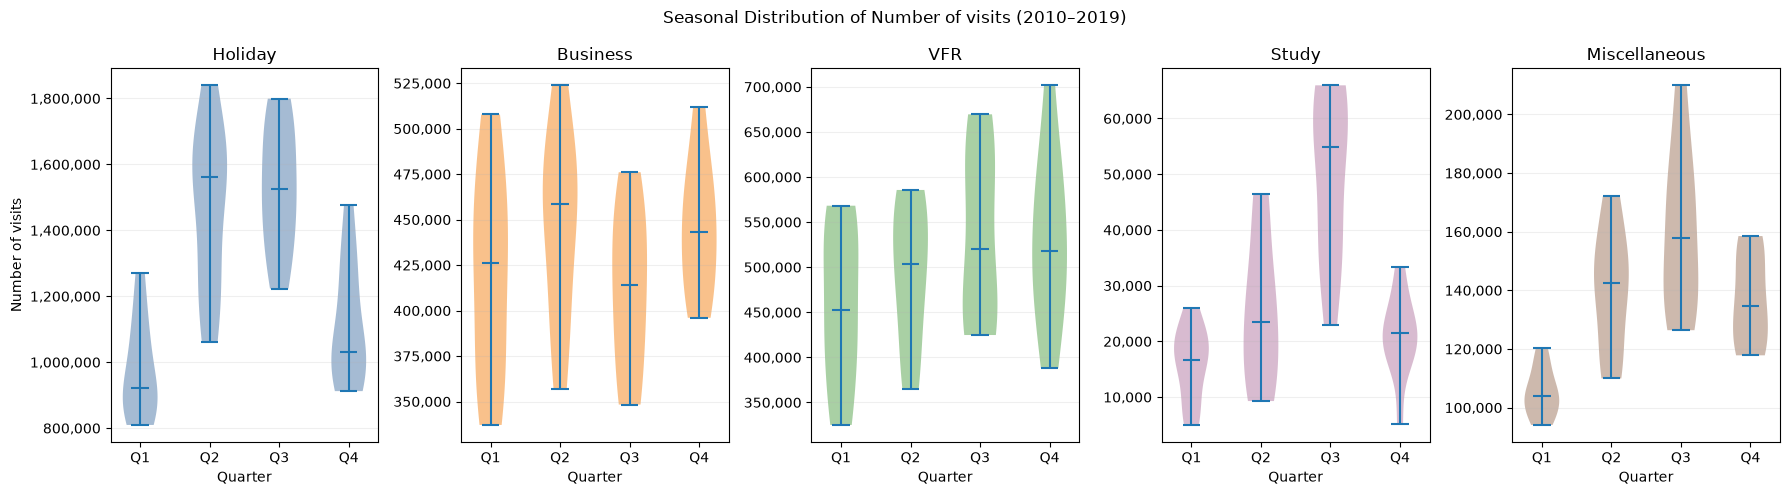

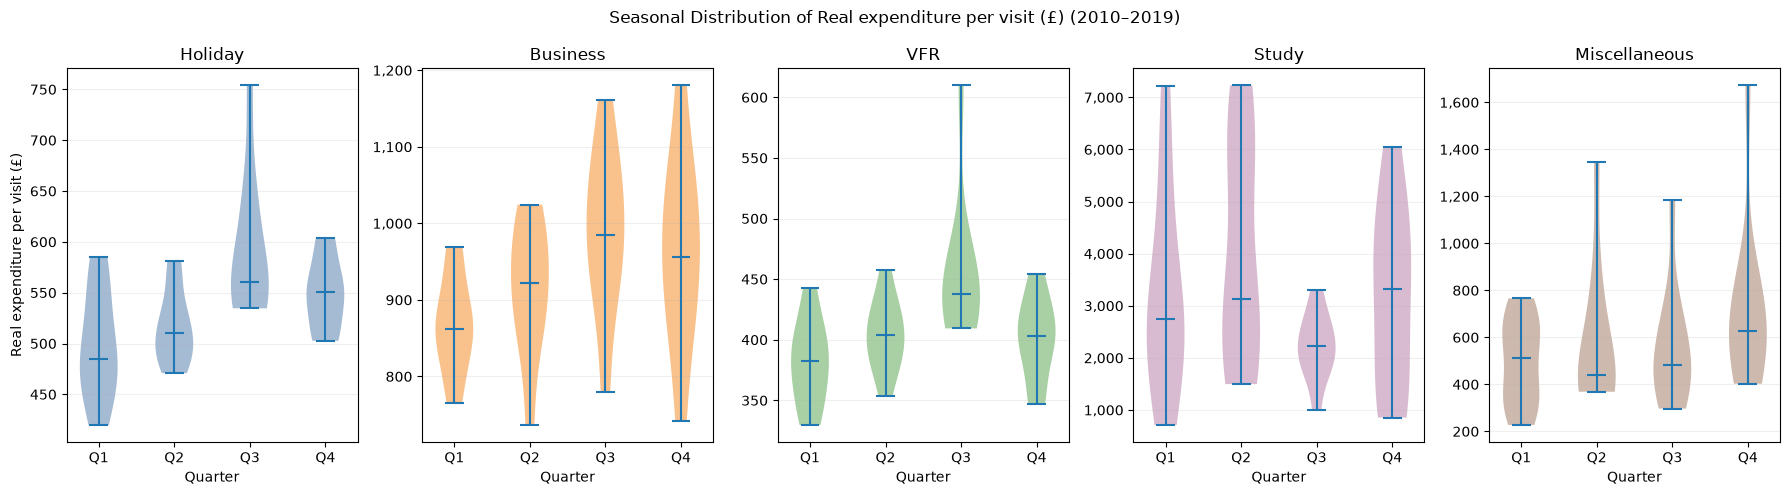

In [146]:
# violin visits graph by quarter for each perpose
plot_seasonal_violin("visits", "Number of visits")
# violin spending per visit graph by quarter for each perpose
plot_seasonal_violin("real_spend_per_visit","Real expenditure per visit (£)")

Seasonal fluctuations appear more pronounced in visitor numbers than in real expenditure per visit for Holiday and Study. Holiday visits exhibit particularly high demand in Q2 and Q3, whereas Study visits show a distinct peak in Q3, potentially reflecting the academic calendar.

Interestingly, despite the substantial increase in study-related visits in Q3, median real expenditure per visit is lower and its distribution is narrower than in other quarters.

Business and VFR visits exhibit less distinct seasonal patterns, although some seasonal differences are observable in expenditure per visit. Miscellaneous visits also show noticeable seasonal variation, with demand peaking in Q3.

However, since the data are aggregated across all selected source markets, differences in country-specific seasonal patterns may offset one another. Furthermore, larger markets may disproportionately influence the aggregated results, potentially masking seasonal characteristics of individual markets.

### 3.4 Cross-market time-series analysis

In [147]:
trend_df = eda_df

In [148]:
def plot_all_purpose_visits(currency):

    market_df = trend_df[
        trend_df["currency"] == currency
    ]

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Complete quarterly timeline
    dates = pd.date_range(
        "2010-01-01", "2019-10-01", freq="QS"
    )

    # Left axis: visits by purpose
    for purpose, color in purpose_colors.items():

        purpose_df = market_df[
            market_df["purpose"] == purpose
        ].set_index("date").reindex(dates)

        ax1.plot(
            purpose_df.index,
            purpose_df["visits"],
            color=color,
            linewidth=2,
            label=purpose
        )

    ax1.set_xlabel("Year")
    ax1.set_ylabel("Number of visits")
    ax1.set_ylim(bottom=0)

    ax1.yaxis.set_major_formatter(
        ticker.StrMethodFormatter("{x:,.0f}")
    )

    # Right axis: exchange rate
    ax2 = ax1.twinx()

    ax2.plot(
        dates,
        fx_df.sort_values(["year", "quarter"])[currency],
        color="black",
        linestyle="--",
        linewidth=2,
        label="Exchange rate"
    )

    ax2.set_ylabel(f"Exchange rate ({currency} per GBP)")

    # Format timeline
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # Combine legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=6
    )

    ax1.grid(alpha=0.2)

    plt.title(
        f"{market_names[currency]}: Quarterly Visits by Purpose "
        f"and Exchange Rate (2010–2019)"
    )

    plt.tight_layout()
    plt.show()

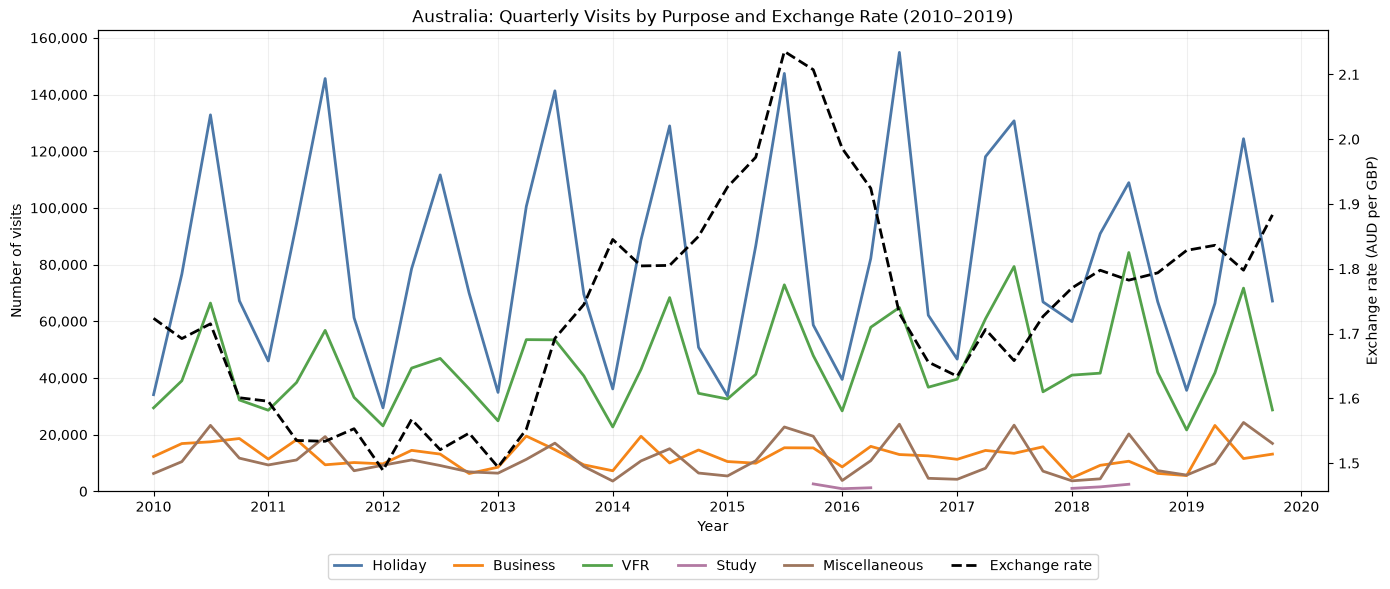

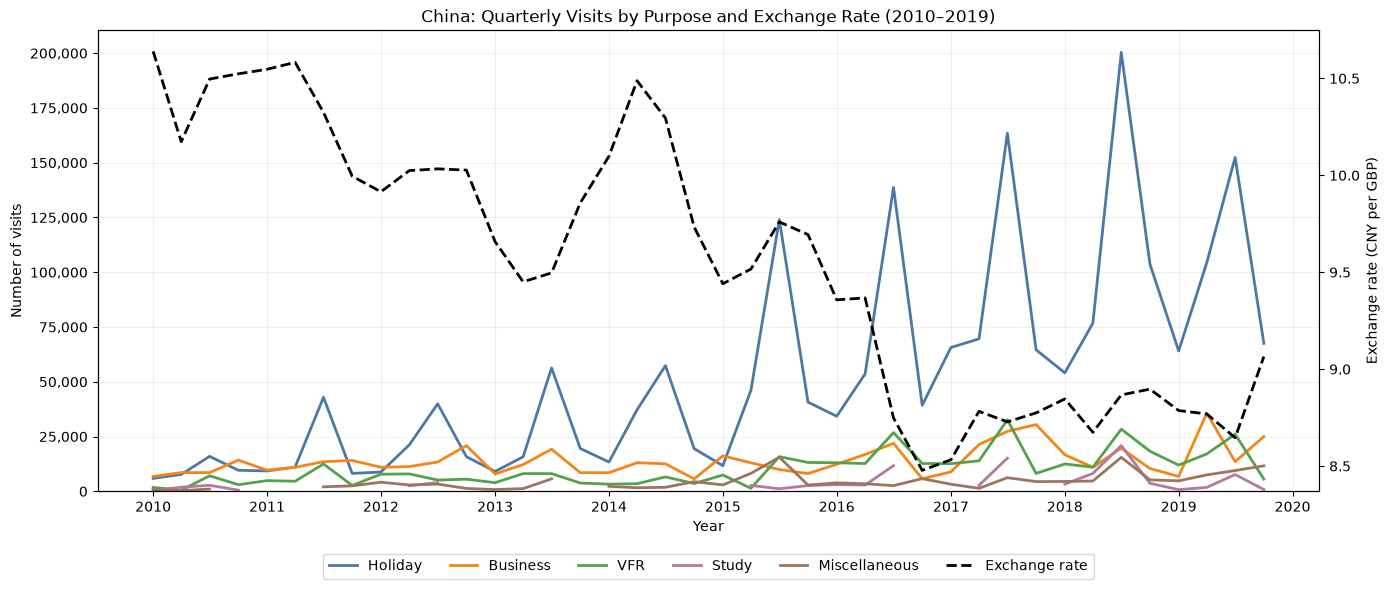

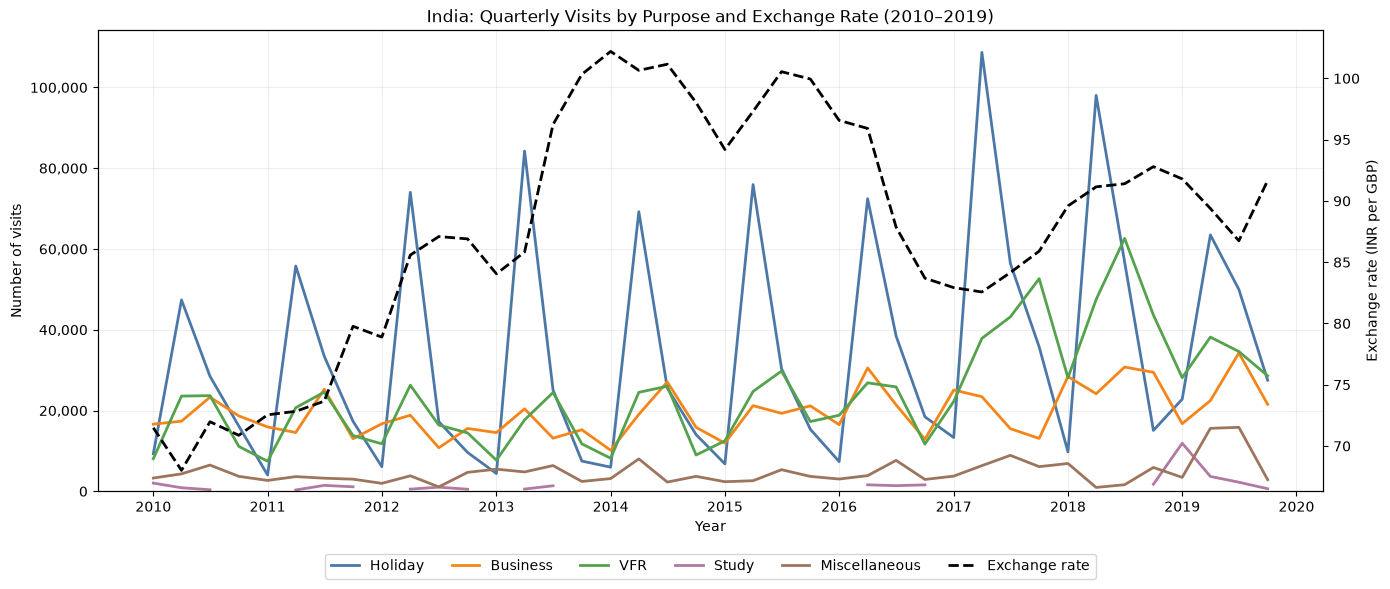

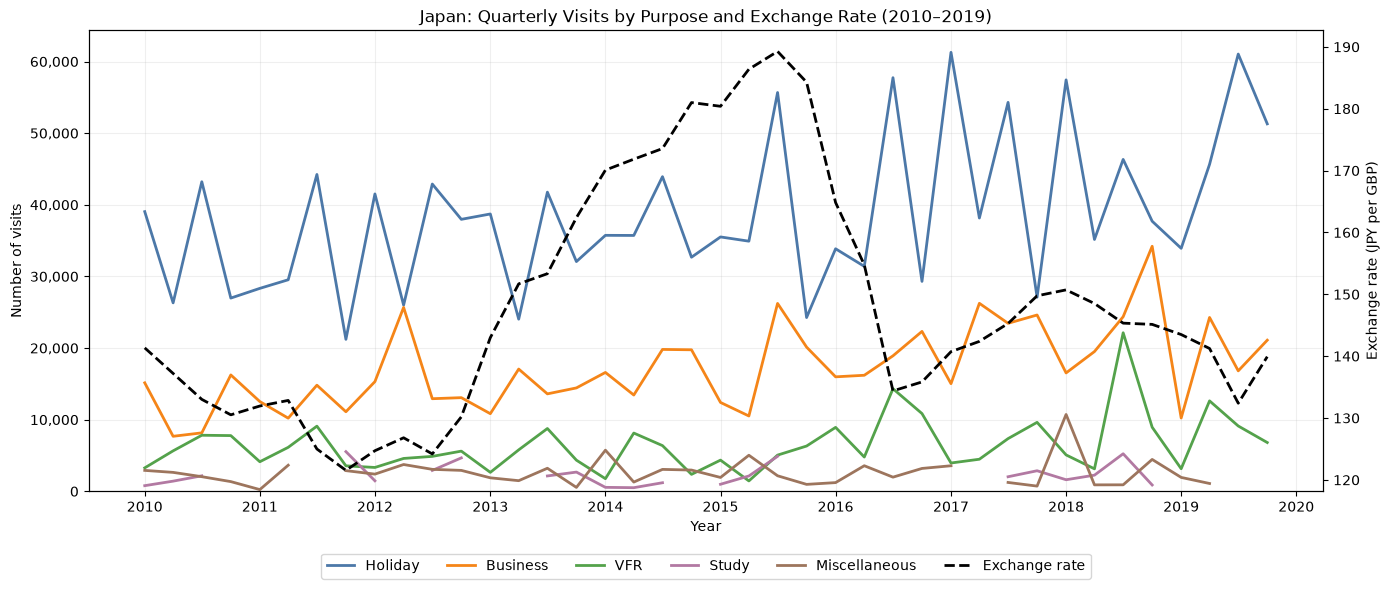

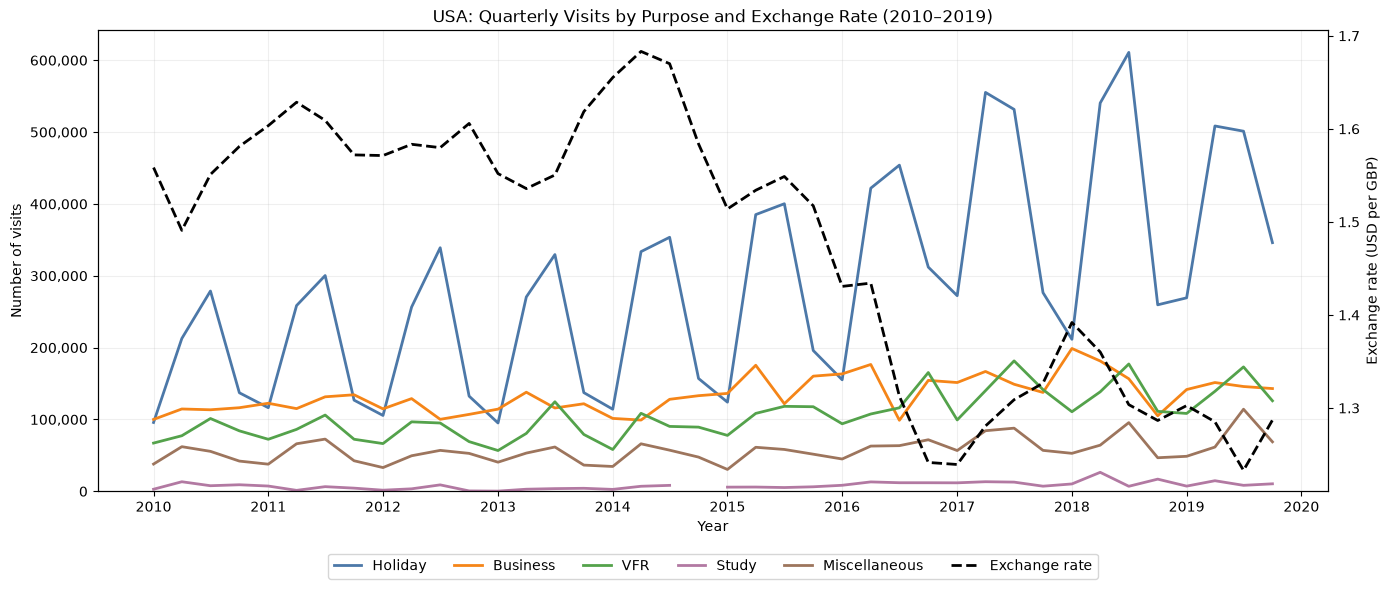

In [149]:
currencies = ["AUD", "CNY", "INR", "JPY", "USD"]

for currency in currencies:
    plot_all_purpose_visits(currency)

Across the selected markets, visitor numbers appear to exhibit a generally negative relationship with exchange rates, particularly for Holiday and VFR visits, although Australia shows a slightly different pattern.

However, Holiday and VFR account for a much larger proportion of total visits than other purposes. As the graphs use the same vertical scale for different visit purposes within each market, fluctuations in categories with fewer visits, such as Business, Study and Miscellaneous, may be less visually apparent.

Furthermore, seasonal fluctuations and long-term changes in visitor demand may influence the observed patterns. Therefore, the visual comparisons alone are insufficient to establish the strength or significance of the relationships.

Further analysis is needed to quantify the associations between exchange rates and visitor numbers, while considering differences across travel purposes and source markets.

### 3.5 Summary of EDA findings